In [ ]:

from google.colab import drive
drive.mount('/content/drive')

!ls "/content/drive/"


Mounted at /content/drive
MyDrive


In [ ]:
!nvidia-smi

Sat Jan 10 15:46:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))
print("GPU Devices:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.19.0
Num GPUs Available: 1
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_CUDNN_AUTOTUNE_DEFAULT'] = '0'

import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

tf.config.optimizer.set_jit(False)

In [ ]:

import numpy as np
import keras
import random
from tqdm.keras import TqdmCallback
import time

from custom_datagen import imageLoader
from model1 import unet_3d
from metrics import IOUScore, FScore, Precision, Recall, DiceScore, MacroDice
from losses import DiceLoss, CategoricalFocalLoss

In [ ]:
# ======== Data Paths ========
"""
train_img_dir = "/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/train/images/"
train_mask_dir = "/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/train/masks/"
val_img_dir = "/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/images/"
val_mask_dir = "/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/masks/"
"""
train_img_dir = "/content/drive/MyDrive/input_data_128/train/images/"
train_mask_dir = "/content/drive/MyDrive/input_data_128/train/masks/"
val_img_dir = "/content/drive/MyDrive/input_data_128/val/images/"
val_mask_dir = "/content/drive/MyDrive/input_data_128/val/masks/"

train_img_list = sorted(os.listdir(train_img_dir))
train_mask_list = sorted(os.listdir(train_mask_dir))
val_img_list = sorted(os.listdir(val_img_dir))
val_mask_list = sorted(os.listdir(val_mask_dir))

batch_size = 2
train_img_datagen = imageLoader(train_img_dir, train_img_list, train_mask_dir, train_mask_list, batch_size)
val_img_datagen = imageLoader(val_img_dir, val_img_list, val_mask_dir, val_mask_list, batch_size)

In [ ]:
dice_loss_fn = DiceLoss()
focal_loss_fn = tf.keras.losses.CategoricalFocalCrossentropy()


class AdaptiveLoss(tf.keras.losses.Loss):
    def __init__(self):
        super().__init__()
        self.epoch = tf.Variable(0, dtype=tf.float32, trainable=False)

    def call(self, y_true, y_pred):
        dice_loss = dice_loss_fn(y_true, y_pred)
        focal_loss = focal_loss_fn(y_true, y_pred)  # no extra args here

        dice_weight = 1.0 / (1.0 + tf.exp(-0.1 * self.epoch))
        focal_weight = 1.0 - dice_weight

        return dice_weight * dice_loss + focal_weight * focal_loss

    def update_epoch(self, new_epoch):
        self.epoch.assign(tf.cast(new_epoch, tf.float32))

adaptive_loss = AdaptiveLoss()


In [ ]:
# ======== Model Setup ========

metrics = [
    'accuracy',
    tf.keras.metrics.OneHotMeanIoU(num_classes=4, ignore_class=0),
    tf.keras.metrics.OneHotIoU(num_classes=4, target_class_ids=[1,2,3]),
    IOUScore(threshold=0.5),
    FScore(beta=1, threshold=0.5),
    Precision(threshold=0.5),
    Recall(threshold=0.5),
    DiceScore(class_indexes=1, threshold=0.5, name='dice_ncr'),
    DiceScore(class_indexes=2, threshold=0.5, name='dice_edema'),
    DiceScore(class_indexes=3, threshold=0.5, name='dice_et'),
    MacroDice(class_indexes=[1,2,3], threshold=0.5, name='macro_dice')
]


LR = 0.0001
optim = keras.optimizers.Adam(LR)
steps_per_epoch = len(train_img_list)//batch_size
val_steps_per_epoch = len(val_img_list)//batch_size

model = unet_3d(IMG_HEIGHT=128,
                IMG_WIDTH=128,
                IMG_DEPTH=128,
                IMG_CHANNELS=3,
                num_classes=4)

model.compile(optimizer=optim, loss=adaptive_loss, metrics=metrics, jit_compile=False)
#model.summary()


In [ ]:
import tensorflow as tf
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

def get_flops_from_model(model):
    # Get model input shape dynamically
    input_shape = [1] + list(model.input_shape[1:])
    concrete_func = tf.function(lambda inputs: model(inputs))
    concrete_func = concrete_func.get_concrete_function(
        tf.TensorSpec(input_shape, tf.float32)
    )

    # Freeze the model graph
    frozen_func = convert_variables_to_constants_v2(concrete_func)
    graph_def = frozen_func.graph.as_graph_def()

    # Import frozen graph into TF1-style graph for profiling
    with tf.Graph().as_default() as graph:
        tf.compat.v1.import_graph_def(graph_def, name='')

        run_meta = tf.compat.v1.RunMetadata()
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

        flops = tf.compat.v1.profiler.profile(
            graph=graph,
            run_meta=run_meta,
            cmd='op',
            options=opts
        )

    return flops.total_float_ops

# Example usage
flops = get_flops_from_model(model)
print(f"Total FLOPs: {flops:,}")
print(f"Approx MACs: {flops / 2:,}")


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


Total FLOPs: 201,153,318,912
Approx MACs: 100,576,659,456.0


In [ ]:
# ======== Save Directories ========
model_save_filepath = "./savepoints2/model"
history_save_filepath = "./savepoints2/history"
os.makedirs(model_save_filepath, exist_ok=True)
os.makedirs(history_save_filepath, exist_ok=True)


# ======== Load previous weights ========
model_file = "/content/drive/MyDrive/input_data_128/model_epoch_155.keras"
model.load_weights(model_file)
model.compile(optimizer=optim, loss=adaptive_loss, metrics=metrics, jit_compile=False)


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 249 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
import os
import numpy as np

# List all .npy files in the directory
all_files = sorted([
    f for f in os.listdir(train_img_dir)
    if f.endswith(".npy")
])

#print(f"Total .npy files found: {len(all_files)}")

# Pick how many you want to load (e.g., 15 or 20)
num_to_load = min(10, len(all_files))

# Load the first few files
selected_files = all_files[:num_to_load]
#print("Files being loaded:")
#for f in selected_files:
#    print(" ", f)

volumes = [np.load(os.path.join(train_img_dir, f)) for f in selected_files]
volumes = np.stack(volumes, axis=0)

print("Volumes stacked with shape:", volumes.shape)


Volumes stacked with shape: (10, 128, 128, 128, 3)


In [ ]:
import tensorflow as tf
import numpy as np
import time
import math
import os

# List all .npy files in the directory
all_files = sorted([
    f for f in os.listdir(train_img_dir)
    if f.endswith(".npy")
])

num_to_load = min(30, len(all_files))

selected_files = all_files[:num_to_load]

volumes = [np.load(os.path.join(train_img_dir, f)) for f in selected_files]
volumes = np.stack(volumes, axis=0)



@tf.function
def infer(x):
    return model(x, training=False)

def measure_inference_time(batch_size, num_runs=20):
    num_batches = math.ceil(len(volumes) / batch_size)
    times = []

    for _ in range(num_runs):
        for b in range(num_batches):
            start_idx = b * batch_size
            end_idx = min((b + 1) * batch_size, len(volumes))
            batch = volumes[start_idx:end_idx]

            start = time.time()
            preds = infer(batch)
            _ = preds.numpy()  # force GPU sync
            end = time.time()

            times.append(end - start)

    avg_batch_time = sum(times) / len(times)
    avg_per_volume = avg_batch_time / batch_size
    return avg_batch_time, avg_per_volume


# Warm-up
_ = infer(volumes[:2])
_ = infer(volumes[:3])

# Measure for batch size 2
batch2_time, per_vol2 = measure_inference_time(batch_size=2)
print(f"Average inference time per batch (2 volumes): {batch2_time:.4f} s")
print(f"Average inference time per volume (batch=2): {per_vol2:.4f} s")

# Measure for batch size 3
batch3_time, per_vol3 = measure_inference_time(batch_size=3)
print(f"\nAverage inference time per batch (3 volumes): {batch3_time:.4f} s")
print(f"Average inference time per volume (batch=3): {per_vol3:.4f} s")


Volumes stacked with shape: (30, 128, 128, 128, 3)
Average inference time per batch (2 volumes): 0.8853 s
Average inference time per volume (batch=2): 0.4427 s

Average inference time per batch (3 volumes): 1.3295 s
Average inference time per volume (batch=3): 0.4432 s


In [ ]:
# ======== Callbacks ========
from tensorflow.keras.callbacks import ModelCheckpoint, Callback
import json

checkpoint_cb = ModelCheckpoint(
    filepath=f"{model_save_filepath}/model_epoch_{{epoch:02d}}.keras",
    save_freq='epoch',
    save_weights_only=False,
    save_best_only=False,
    verbose=1
)

class SaveHistoryCallback(Callback):
    def on_epoch_end(self, epoch, logs=None):
        file_path = f"{history_save_filepath}/history_epoch_{epoch + 1:02d}.json"
        with open(file_path, 'w') as f:
            json.dump(self.model.history.history, f)

class UpdateEpochCallback(tf.keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        adaptive_loss.update_epoch(epoch)

# ======== Train Model ========
history = model.fit(
    train_img_datagen,
    steps_per_epoch=steps_per_epoch,
    epochs=155,
    initial_epoch=149,
    verbose=1,
    validation_data=val_img_datagen,
    validation_steps=val_steps_per_epoch,
    callbacks=[
        TqdmCallback(verbose=0),
        checkpoint_cb,
        SaveHistoryCallback(),
        UpdateEpochCallback()
    ]
)

0epoch [00:00, ?epoch/s]

Epoch 150/155
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.8214 - dice_edema: 0.0140 - dice_et: 0.0050 - dice_ncr: 0.0072 - f1_score: 0.1368 - iou_score: 0.1177 - loss: 0.8509 - macro_dice: 0.0087 - one_hot_io_u: 0.0041 - one_hot_mean_io_u: 0.0148 - precision: 0.4562 - recall: 0.1331
Epoch 150: saving model to ./savepoints2/model/model_epoch_150.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 461s 13s/step - accuracy: 0.8219 - dice_edema: 0.0141 - dice_et: 0.0051 - dice_ncr: 0.0071 - f1_score: 0.1400 - iou_score: 0.1212 - loss: 0.8498 - macro_dice: 0.0087 - one_hot_io_u: 0.0041 - one_hot_mean_io_u: 0.0149 - precision: 0.4502 - recall: 0.1365 - val_accuracy: 0.9480 - val_dice_edema: 0.0184 - val_dice_et: 1.7872e-10 - val_dice_ncr: 2.5148e-10 - val_f1_score: 0.2471 - val_iou_score: 0.2378 - val_loss: 0.7520 - val_macro_dice: 0.0061 - val_one_hot_io_u: 0.0033 - val_one_hot_mean_io_u: 0.0040 - val_precision: 0.2445 - val_recall: 0.2501
Epoch 151/155
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accurac

In [ ]:
from keras.metrics import MeanIoU

batch_size=2 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Mean IoU = 0.7619568


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step


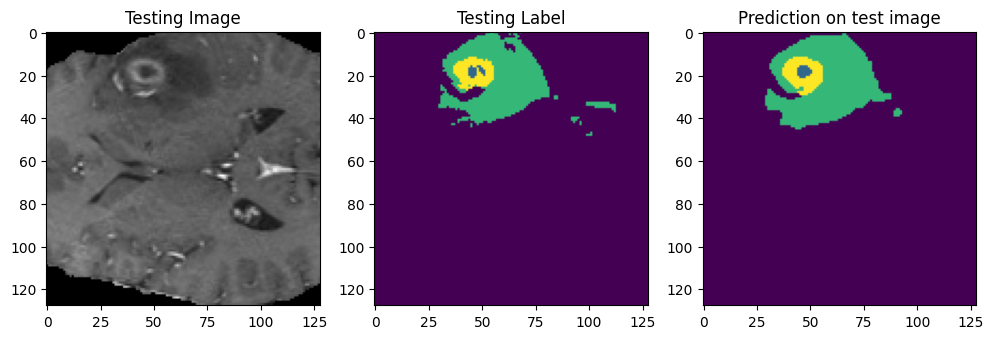

In [ ]:
img_num = 1


test_img = np.load("/content/drive/MyDrive/input_data_128/train/images/image_"+str(img_num)+".npy")

test_mask = np.load("/content/drive/MyDrive/input_data_128/train/masks/mask_"+str(img_num)+".npy")
"""
test_img = np.load("/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/masks/mask_"+str(img_num)+".npy")
"""
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]


# print(test_prediction_argmax.shape)
# print(test_mask_argmax.shape)
# print(np.unique(test_prediction_argmax))


#Plot individual slices from test predictions for verification
from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

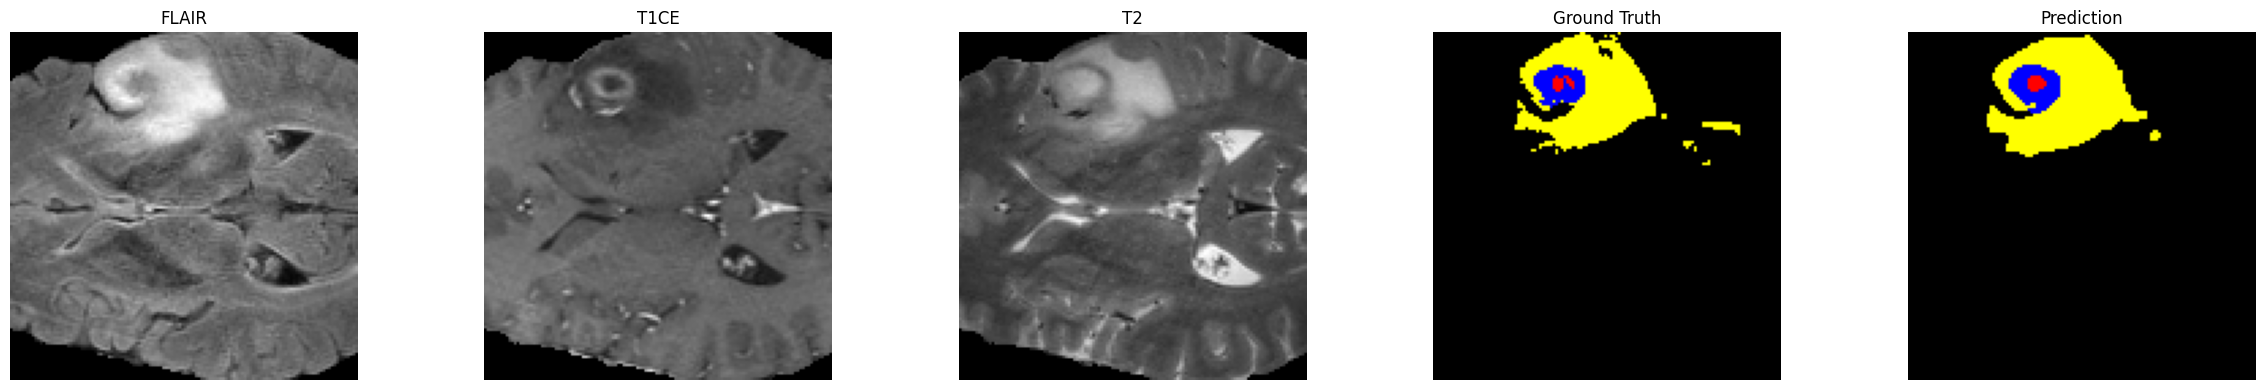

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap

tumor_cmap = ListedColormap([
    'black',     # Background
    'red',       # NCR / NET
    'yellow',    # Edema
    'blue'       # Enhancing Tumor
])


# Select slice
n_slice = 55

plt.figure(figsize=(24, 4))

# FLAIR
plt.subplot(1, 5, 1)
plt.imshow(test_img[:, :, n_slice, 0], cmap='gray')
plt.title("FLAIR")
plt.axis('off')

# T1CE
plt.subplot(1, 5, 2)
plt.imshow(test_img[:, :, n_slice, 1], cmap='gray')
plt.title("T1CE")
plt.axis('off')

# T2
plt.subplot(1, 5, 3)
plt.imshow(test_img[:, :, n_slice, 2], cmap='gray')
plt.title("T2")
plt.axis('off')

# Ground Truth Mask
plt.subplot(1, 5, 4)
plt.imshow(test_mask_argmax[:, :, n_slice], cmap=tumor_cmap, vmin=0, vmax=3)
plt.title("Ground Truth")
plt.axis('off')

# Predicted Mask
plt.subplot(1, 5, 5)
plt.imshow(test_prediction_argmax[:, :, n_slice], cmap=tumor_cmap, vmin=0, vmax=3)
plt.title("Prediction")
plt.axis('off')

plt.tight_layout()
plt.show()


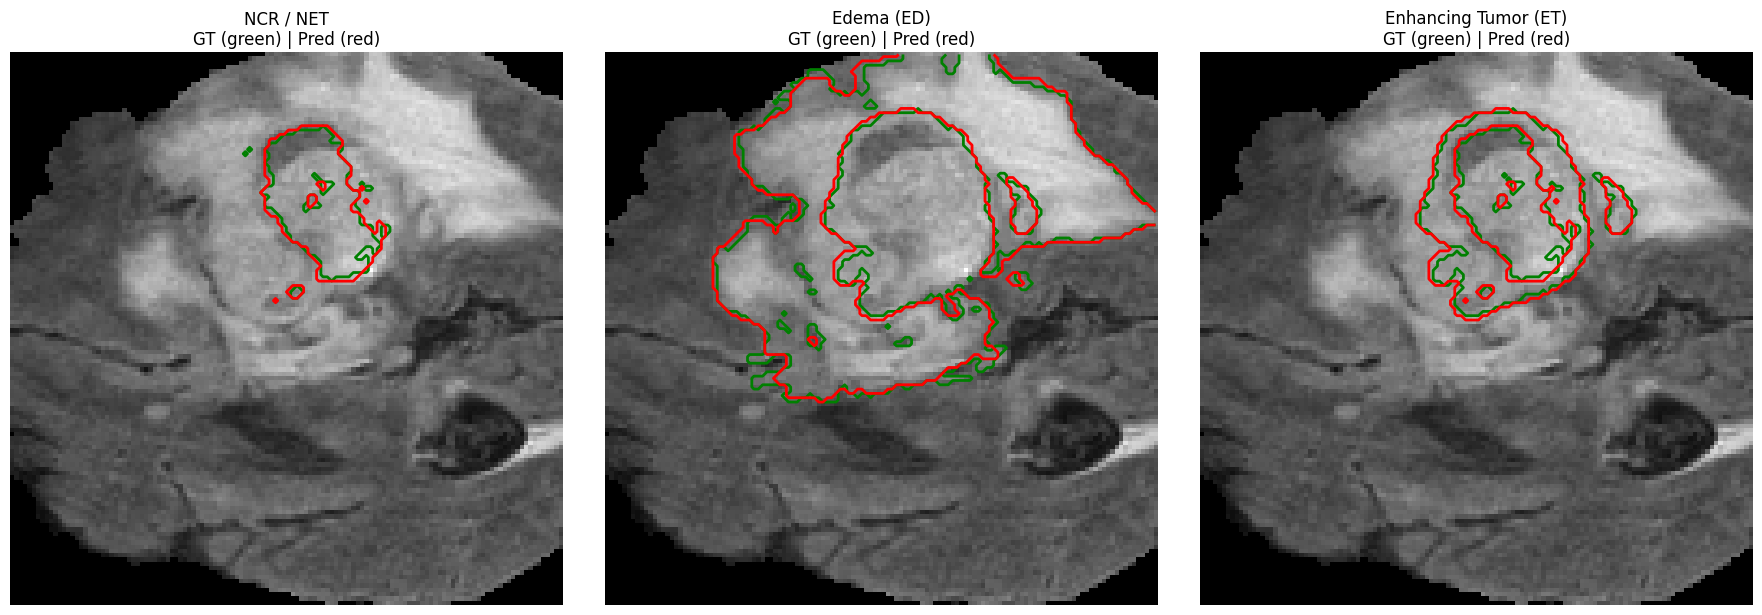

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------
# Settings
# -----------------------
n_slice = 55
modality_channel = 0  # 0 = FLAIR
class_names = {
    1: "NCR / NET",
    2: "Edema (ED)",
    3: "Enhancing Tumor (ET)"
}

# -----------------------
# Figure
# -----------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (cls, name) in zip(axes, class_names.items()):
    # Base FLAIR image
    ax.imshow(test_img[:, :, n_slice, modality_channel], cmap="gray")

    # Ground truth contour (green)
    ax.contour(
        (test_mask_argmax[:, :, n_slice] == cls).astype(np.uint8),
        levels=[0.5],
        colors="green",
        linewidths=2
    )

    # Prediction contour (red)
    ax.contour(
        (test_prediction_argmax[:, :, n_slice] == cls).astype(np.uint8),
        levels=[0.5],
        colors="red",
        linewidths=2
    )

    ax.set_title(f"{name}\nGT (green) | Pred (red)", fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.show()


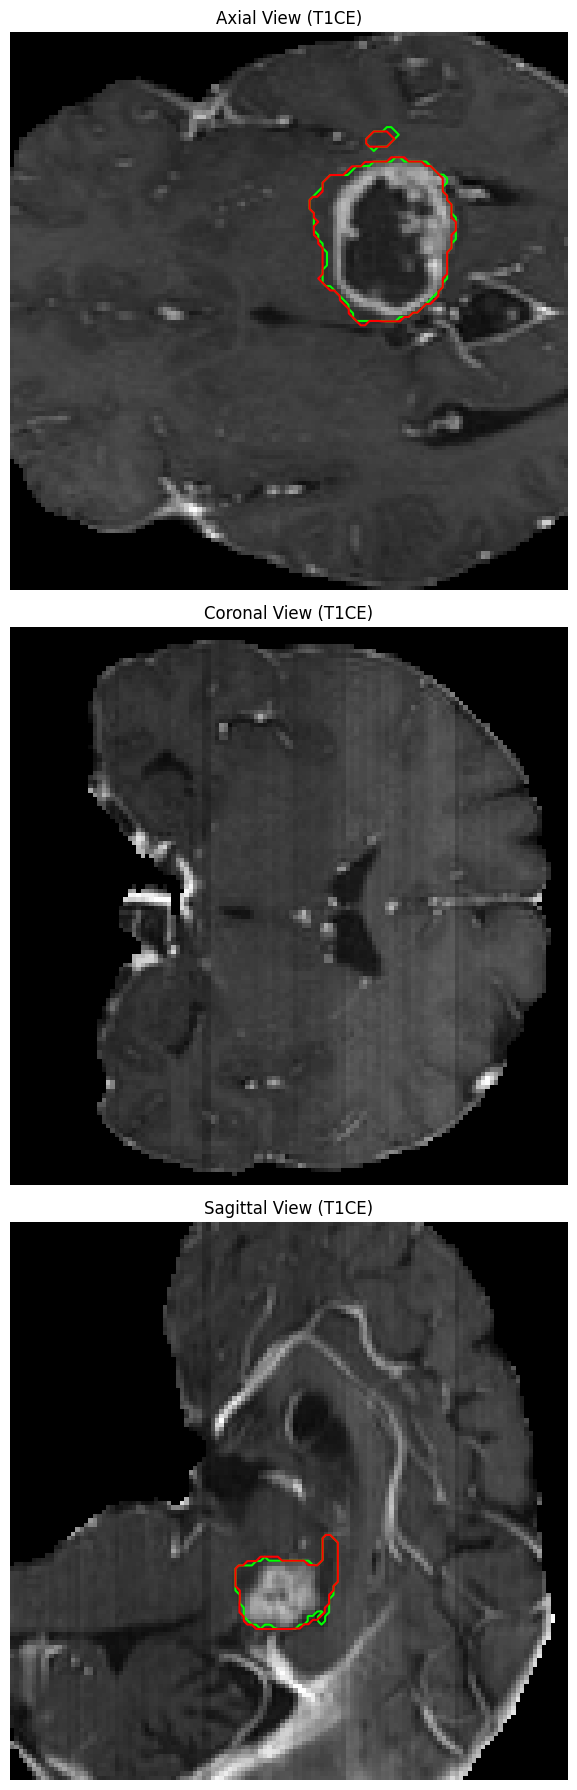

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------
# Slice indices
# -----------------------
axial_slice = 55
coronal_slice = test_img.shape[1] // 2
sagittal_slice = test_img.shape[0] // 2

# -----------------------
# Select modality
# Channel mapping:
# 0 = FLAIR, 1 = T1CE, 2 = T2
# -----------------------
modality_channel = 1  # T1CE

# -----------------------
# Figure setup
# -----------------------
fig, axes = plt.subplots(3, 1, figsize=(6, 18))

# -----------------------
# Helper function
# -----------------------
def plot_contour(ax, image, gt, pred, title):
    ax.imshow(image, cmap='gray')
    ax.contour(gt, levels=[0.5], colors='lime', linewidths=1.5)
    ax.contour(pred, levels=[0.5], colors='red', linewidths=1.5)
    ax.set_title(title, fontsize=12)
    ax.axis('off')

# -----------------------
# Axial view
# -----------------------
plot_contour(
    axes[0],
    test_img[:, :, axial_slice, modality_channel],
    test_mask_argmax[:, :, axial_slice],
    test_prediction_argmax[:, :, axial_slice],
    "Axial View (T1CE)"
)

# -----------------------
# Coronal view
# -----------------------
plot_contour(
    axes[1],
    test_img[:, coronal_slice, :, modality_channel],
    test_mask_argmax[:, coronal_slice, :],
    test_prediction_argmax[:, coronal_slice, :],
    "Coronal View (T1CE)"
)

# -----------------------
# Sagittal view
# -----------------------
plot_contour(
    axes[2],
    test_img[sagittal_slice, :, :, modality_channel],
    test_mask_argmax[sagittal_slice, :, :],
    test_prediction_argmax[sagittal_slice, :, :],
    "Sagittal View (T1CE)"
)

plt.tight_layout()

# -----------------------
# Save publication-quality figures
# -----------------------
plt.savefig("segmentation_multiview_contours.png", dpi=300, bbox_inches="tight")
plt.savefig("segmentation_multiview_contours.pdf", dpi=300, bbox_inches="tight")

plt.show()


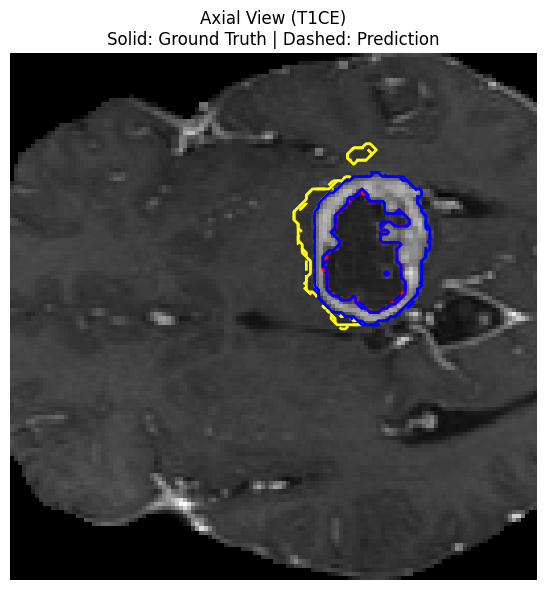

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
CLASS_COLORS = {
    1: "red",     # NCR / NET
    2: "yellow",  # Edema
    3: "blue"     # Enhancing Tumor
}


# Select slice and modality
n_slice = 55
modality_channel = 1  # 0=FLAIR, 1=T1CE, 2=T2

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# Base MRI image
ax.imshow(test_img[:, :, n_slice, modality_channel], cmap="gray")

# Plot contours for each tumor class
for cls, color in CLASS_COLORS.items():
    # Ground truth contour (solid)
    ax.contour(
        (test_mask_argmax[:, :, n_slice] == cls).astype(np.uint8),
        levels=[0.5],
        colors=color,
        linewidths=2,
        linestyles="solid"
    )

    # Prediction contour (dashed)
    ax.contour(
        (test_prediction_argmax[:, :, n_slice] == cls).astype(np.uint8),
        levels=[0.5],
        colors=color,
        linewidths=2,
        linestyles="dashed"
    )

ax.set_title("Axial View (T1CE)\nSolid: Ground Truth | Dashed: Prediction", fontsize=12)
ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
img_num = 36
"""
test_img = np.load("/content/drive/MyDrive/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("/content/drive/MyDrive/input_data_128/val/masks/mask_"+str(img_num)+".npy")
"""
test_img = np.load("/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]


# print(test_prediction_argmax.shape)
# print(test_mask_argmax.shape)
# print(np.unique(test_prediction_argmax))


#Plot individual slices from test predictions for verification
from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

In [ ]:
img_num = 37
"""
test_img = np.load("/content/drive/MyDrive/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("/content/drive/MyDrive/input_data_128/val/masks/mask_"+str(img_num)+".npy")
"""
test_img = np.load("/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/masks/mask_"+str(img_num)+".npy")

test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]


# print(test_prediction_argmax.shape)
# print(test_mask_argmax.shape)
# print(np.unique(test_prediction_argmax))


#Plot individual slices from test predictions for verification
from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

In [ ]:
img_num = 411
"""
test_img = np.load("/content/drive/MyDrive/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("/content/drive/MyDrive/input_data_128/val/masks/mask_"+str(img_num)+".npy")
"""
test_img = np.load("/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("/home/db-drdo/Workspaces/Arkaprabha Laha/data/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]


# print(test_prediction_argmax.shape)
# print(test_mask_argmax.shape)
# print(np.unique(test_prediction_argmax))


#Plot individual slices from test predictions for verification
from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

In [ ]:
print(test_mask.shape)
print(np.unique(test_mask))
print(np.unique(test_mask_argmax))